---
title: "The grain model: a solid made of shrinking cores, and the exact penetration law inside it"
description: "Szekely and Evans replaced the shrinking-core model's empirical rate constant with structure: porosity, grain size, two diffusivities and a rate constant that no longer depends on the solid. The page rebuilds their grain model with pymrm, derives the exact closed-form penetration law their quasi-steady equations imply, and shows the model collapsing onto the published B3.1 shrinking core at the exposed face."
categories: [sec:B, struct:S3, struct:S12, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-05
---

# The grain model: a solid made of shrinking cores, and the exact penetration law inside it

**Catalog ID:** `B3.2` · **Structures:** `S3` (1-D reaction-diffusion BVP) + `S12`
(moving boundary) · **Tier:** T0

A porous ore pellet is not a solid lump with a sharp reaction front. Szekely and
Evans' 1970 paper models it as what it is under the microscope: a packing of
small dense **grains**, each one a shrinking core, all of them fed by gas
diffusing through the interstices. Reaction then happens in a **diffuse zone**
whose thickness the shrinking-core picture cannot even express, and the rate
"constant" measured by fitting a shrinking-core model stops being a property of
the chemistry and becomes a property of the microstructure.

Their motivation is stated in the abstract: the shrinking core model buries
structural parameters "into an empirical reaction rate constant", whereas here
the reaction is described "in terms of the porosity, grain size, gas phase and
solid state diffusivities and a heterogeneous reaction rate constant, **which is
now independent of structure**".

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.10.3"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B3.2-grain-model"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page's model.py is put on sys.path by setup().
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import observed_orders
from gallery_utils import Claims, load_claims
from model import (E_exact, G_of_xi, GrainModel, X_of_theta, departure_thetas, lag,
                   profile_exact, scales, xi_of_zeta, yagi_kunii_eq6, zone_width)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
B31 = load_claims("B3.1-shrinking-core")   # the shrinking-core page this model reduces to
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))

## Background

The classical description of a gas-solid reaction with a moving boundary is the
shrinking core model, the gallery's published
[`B3.1`](../B3.1-shrinking-core/): three resistances in series and a sharp
interface. Szekely and Evans open by naming its two shortcomings (their §1):
the reacted and unreacted zones "are not necessarily separated by a sharp
boundary, in fact under certain conditions the reaction is found to occur in a
diffuse zone, the thickness of which may be of the same order as the size of
the reacting specimen"; and the fitted rate constants "must be dependent on the
solid structure … no unique reaction rate constant can be assigned to a given
ore or sinter".

The paper proposes two structural models, a **pore model** (parallel
cylindrical pores) and a **grain model** (a packing of spherical grains), and
shows they behave almost identically. This page builds the **grain model**,
which became the canonical one: the solid is spherical grains of radius $R_g$;
gas diffuses through the interstices with an effective diffusivity $D'$; each
grain is consumed as a little shrinking core with product-layer diffusivity $D$
and first-order surface rate constant $k$.

Two honesty notes the page carries from the source. First, the paper's own
validation claim is deliberately modest: "By taking 'reasonable values' for
these parameters the model was found to reproduce the **general trends**
exhibited by the experimental data of other investigators." That is a trend
claim, not a fit, and nothing on this page presents it as a validated
prediction. Second, this Part I treats a **semi-infinite** solid with a planar
exposed face; the finite spherical pellet is Part II (*Chem. Eng. Sci.* **26**
(1971) 1901), which is not available to this gallery as a readable scan and is
not used here.

## The published model

All equations below were transcribed from renders of the scan at its native
300 ppi (CCITT-G4 bilevel; rendering higher is interpolation). The text layer of
this 1970 Pergamon scan is unusable for mathematics (it returns Eq. 21's
denominator as `R R ~ _1 P [ _ D DR$+k` and drops the mid-dot decimal points
from the figure captions), so nothing here comes from OCR.

**Porosity** (Eq. 20): each volume element $L'^3$ holds $N$ grains of radius
$R_g$,

$$S_g = 1 - \tfrac{4}{3}\pi \frac{R_g^3}{L'^3}N .$$

**Grain consumption** (Eq. 21, with its printed constraint): for a grain
surrounded by gas at concentration $C'_{p}$, quasi-steady diffusion through its
product shell in series with the surface reaction gives

$$-\frac{\mathrm{d}R'}{\mathrm{d}t}
 = \frac{C'_{p}}
        {\rho\left[\dfrac{R'}{D}-\dfrac{R'^2}{D R_g}+\dfrac{1}{k}\right]};
 \qquad 0 \le R' \le R_g ,$$

where $R'$ is the unreacted-core radius and $\rho$ the molar density of the
solid reactant. The initial condition is $R' = R_g$ (Eq. 22).

**Gas phase** (Eq. 27, the continuum form of the row-by-row balance Eq. 24):

$$D'\,\frac{\partial^2 C'_p}{\partial y^2}
 = \frac{3R'(y)\,(1-S_g)\,D\;C'_p(y)}
        {R_g^{\,3}\left[1-\dfrac{R'(y)}{R_g}+\dfrac{D}{R'(y)\,k}\right]} ,$$

with $C'_p = C_0$ at $y=0$ (Eq. 28) and $C'_p \to 0$ as $y\to\infty$ (Eq. 29).
The equation is **quasi-steady**: gas holdup in the pores is neglected
against the solid inventory. Eqs. 21 and 27 print the *same* series resistance
in two different algebraic arrangements; a transcription slip in either one
would make gas consumption and solid consumption inconsistent, which the
mass-balance check below detects (break table).

**Extent of reaction** (Eq. 34): the *equivalent penetration*, the depth of a
fully-reacted layer containing the same amount of reacted solid,

$$\mathrm{E.P.} = \int_{y=0}^{\infty} \frac{R_g^3 - R'^3(y)}{R_g^3}\,\mathrm{d}y .$$

**Effective diffusivity** (Appendix 2): $D' = P D_p / F_T$ with the porosity
substituted for $P$ and a tortuosity factor $F_T = 2.75$.

### The dimensionless form

With
$$\xi = \frac{R'}{R_g},\qquad
\psi = \frac{C'_p}{C_0},\qquad
\eta = \frac{y}{\ell},\qquad
\theta = \frac{t}{\tau},$$

$$\ell = \sqrt{\frac{D' R_g}{3(1-S_g)k}},\qquad
\tau = \frac{\rho R_g}{k C_0},\qquad
\boxed{\;g = \frac{k R_g}{D}\;}$$

the whole model collapses to **one parameter** $g$, the ratio of product-shell
to surface-reaction resistance at the grain scale:

$$\frac{\partial^2\psi}{\partial\eta^2}
   = \frac{\xi^2\,\psi}{1+g\,\xi(1-\xi)},\qquad
  \frac{\partial \xi}{\partial\theta} = -\frac{\psi}{1+g\,\xi(1-\xi)}
  \;\;(\xi \ge 0),\qquad
  E \equiv \frac{\mathrm{E.P.}}{\ell} = \int_0^\infty (1-\xi^3)\,\mathrm{d}\eta .$$

### The exact solution the quasi-steady equations imply

Because the gas equation is quasi-steady and the kinetics first order, the model
is integrable, a consequence the source does not use. Define the local
**exposure** $\zeta(\eta,\theta) = \int_0^\theta \psi\,\mathrm{d}\theta'$.
The grain ODE integrates pointwise to

$$G(\xi) \equiv (1-\xi) + \frac{g}{6}\left(1-3\xi^2+2\xi^3\right) = \zeta ,$$

so the local core radius is a function of local exposure alone, and every grain
is fully consumed when its exposure reaches $\theta^{\ast} = G(0) = 1+g/6$.
Integrating the gas equation in time gives a *single autonomous BVP for the
exposure field*,

$$\frac{\partial^2\zeta}{\partial\eta^2} = \frac{x(\zeta)}{3},
\qquad x(\zeta) = 1-\xi^3(\zeta),\qquad \zeta(0,\theta)=\theta,\ \ \zeta(\infty)=0,$$

whose first integral, $\partial\zeta/\partial\eta = -\sqrt{2X(\zeta)/3}$, yields a
**closed-form penetration law**:

$$\boxed{\;E(\theta) = \sqrt{6\,X(\theta)}\;},\qquad
X(\theta) = \int_0^\theta x(s)\,\mathrm{d}s ,$$

with $X$ itself a closed-form polynomial in the converted fraction of the
surface grain radius $u_\theta = 1-\xi_\theta$, $\xi_\theta = G^{-1}(\theta)$:
substituting $s = G(\xi)$ turns the integral into
$\int (1-\xi^3)(1+g\xi-g\xi^2)\,\mathrm{d}\xi$, and written in $u$,
$G = u + g u^2/2 - g u^3/3$ and
$X = \tfrac32 u^2 + (g-1)u^3 + \tfrac{1-6g}{4}u^4 + \tfrac45 g u^5 - \tfrac{g}{6}u^6$,
with no cancellation at small exposure. The gas profile is exact too:
$\psi = \sqrt{X(\zeta)/X(\theta)}$. Both limits fall out:

* **early / kinetic**: $E \to 3\theta$, the exponential initial profile
  (the grain-model analogue of the paper's Eq. 18) eating every grain in place;
* **late / diffusion through the reacted layer**:
  $E = \sqrt{6(\theta-\Delta)}$ **exactly** for $\theta \ge \theta^{\ast}$, with a lag
  $\Delta = \theta^{\ast} - X(\theta^{\ast}) = \tfrac14 + \tfrac{g}{30}$: the sharp-interface
  shrinking core of the *whole specimen*, which is the classical picture the
  paper set out to generalise.

Since the slope $\partial\zeta/\partial\eta$ depends on $\zeta$ alone, the
exposure profile is a **travelling wave**: its shape never changes, it only
moves inward. Every distance between two exposure levels, the width of the
reaction zone included, is therefore exactly constant in time once both levels
exist.

This closed form is derived here from Eqs. 21 + 27; it is the second,
independent route against which the pymrm solve is judged, and it is a close
relative of the additive-reaction-time law Sohn later built on this model
(planned page `B3.4`, which cites this paper).

### The reduction to the published `B3.1`

At the exposed face $\psi \equiv 1$, so the surface grains see constant gas:
exactly `B3.1`'s single shrinking core with no film resistance. And indeed
$G(\xi)/\theta^{\ast}$ is **term for term** Yagi & Kunii's Eq. 6 in its no-film
limit, with `B3.1`'s groups $\omega = k_{c1}/k_{d1}$, $k_{d1}=12\mathbb{D}/D_p$
evaluating to $\omega = g/6$:

$$\frac{\theta}{\theta^{\ast}} =
\frac{(1-\xi) + \omega\,(1-3\xi^2+2\xi^3)}{1+\omega},\qquad \omega=\frac{g}{6}.$$

Two different papers, read into two different gallery pages, print the same
function; the identity, and the simulated surface-grain history landing on it,
are checked below.

## Parameters and assumptions

**The paper's assumptions** (its §2, numbered as printed): (1) no gas-film
resistance at the exposed face; (2) semi-infinite solid, macroscopically
one-dimensional; (3) first-order irreversible reaction, equimolar or dilute so
bulk flow is negligible; (4) isothermal; (5) the initial structure persists:
no sintering, swelling or pore closure. Assumption (5) is the one the authors
themselves flag as the most serious limitation. Additional to these:
quasi-steady gas phase, and the cavities as "perfect mixers" (their Eq. 23-24
picture, taken to the continuum in Eq. 27).

**What the paper prints as numbers**, all read off native-resolution crops:

* Figure 7 (grain-model base case): $D_p = 8.0$ cm²/s, $R_g = 5.0\times10^{-3}$
  cm, $D = 2.0\times10^{-4}$ cm²/s, $k = 20.0$ cm/s, porosity 25 %.
* Table 1 (grain-model ranges): $R_g$ = 1-500 μ; $S_g$ = 12.5, 25.0, 50.0 %;
  $D$ = 2×10⁻⁷ … 2×10⁻¹ cm²/s; $D_p$ = 4.0-10.0 cm²/s;
  $k$ = 0.005, 0.02, 0.2, 20.0 cm/s (the Fig. 19 sweep).
* Appendix 2: $F_T = 2.75$; Fig. 5's inset prints $\rho = 0.07$ g mol/cm³ for
  the pore-model contour computation; the text brackets practical solids as
  $0.01 < \rho < 0.1$ g mol/cm³.

**What the paper never prints: $C_0$.** Every E.P.-time result is plotted
against $t/\rho$, and the bulk gas concentration used in the computations is
stated nowhere. Since time enters the model only as $kC_0t/(\rho R_g)$, the
absolute abscissa of Figs. 6-19 cannot be reconstructed from the printed text,
and this page does not attempt it, the same refusal as `B3.1`'s missing unit
conversion. Everything runs in the model's own dimensionless groups, where the
paper's printed parameter sets translate cleanly: the four printed rate
constants of the Fig. 19 sweep give, at the base-case $R_g$ and $D$, the four
values of $g$ printed below, and the Fig. 7 base case is the largest. Those four
$g$ values are used throughout this page, so every curve below is anchored to a
printed parameter set. (One deliberately *chosen* value appears in the
dimensional check below, and is labelled there.)

**Fitted: nothing.** No constant on this page is adjusted to make any
comparison work; the only least-squares operation is a diagnostic mean of the
page's *own computed* late-time asymptote, with a stated window.

In [3]:
FIG7 = dict(Dp=8.0, Rg=5.0e-3, D=2.0e-4, k=20.0, Sg=0.25, FT=2.75)  # Fig. 7 caption, cgs
K_SWEEP = [0.005, 0.02, 0.2, 20.0]           # Fig. 19 / Table 1, cm/s
G_SWEEP = [kk * FIG7["Rg"] / FIG7["D"] for kk in K_SWEEP]
RHO = 0.07     # g mol/cm3, printed in Fig. 5's inset
C0 = 1.0e-5    # g mol/cm3, CHOSEN (not printed): enters only the dimensional check
SC = scales(**FIG7, rho=RHO, C0=C0)
ell = SC["ell"]
print("printed Fig. 7 base case ->  D' = Sg*Dp/FT = %.4f cm^2/s" % SC["Deff"])
print("length scale ell = sqrt(D' Rg / (3(1-Sg)k)) = %.4e cm" % ell)
print("g = k Rg / D for the printed k-sweep {0.005, 0.02, 0.2, 20} cm/s:",
      [f"{gg:g}" for gg in G_SWEEP])
print("theta* = 1 + g/6 (surface burnout):", [f"{1 + gg / 6:g}" for gg in G_SWEEP])

printed Fig. 7 base case ->  D' = Sg*Dp/FT = 0.7273 cm^2/s
length scale ell = sqrt(D' Rg / (3(1-Sg)k)) = 8.9893e-03 cm
g = k Rg / D for the printed k-sweep {0.005, 0.02, 0.2, 20} cm/s: ['0.125', '0.5', '5', '500']
theta* = 1 + g/6 (surface burnout): ['1.02083', '1.08333', '1.83333', '84.3333']


## The data

**There is none, and the split is precise.** What the paper *prints as numbers*
is listed above: figure-caption parameter sets, Table 1's ranges, $F_T$, and
the closed forms (Eqs. 19-34). Every computed *result*, all the E.P.-time
curves of Figs. 5-19, exists **only as figures**, and the paper contains no
experimental measurements at all (its comparison with "the experimental data of
other investigators" is the trend statement quoted above, made against
literature it cites, not against tables it prints).

No figure is digitised for this page. Two reasons, in order: the validation
available *without* any figure, an exact closed form plus reduction to the
independently published `B3.1`, ranks higher than a digitised curve in this
gallery's hierarchy; and a figure route would require a maintainer review gate
for which no maintainer is currently available. Since $C_0$ is unprinted, a
digitised ordinate could in any case only be compared up to an unknown scale
factor on the time axis.

This page is therefore provenance **tier 6** by necessity, like `B3.1`. Nothing
below is fitted to anything; *fit vs test* reduces to "everything is test".

## PyMRM implementation

Two independent routes to the same model, both in `model.py`.

**Route 1, the exact closed form** derived above (`E_exact`, `X_of_theta`,
`profile_exact`, `zone_width`): polynomials, a scalar inversion of $G$, a
square root, and for the profiles one ODE in $u$ integrated by DOP853 at the
requested depths. No grid, no time march, no linear algebra.

**Route 2, the paper's own formulation marched with pymrm** (`GrainModel`), as
Szekely and Evans did numerically (their Appendix 1: a two-point BVP coupled to
the interface ODEs). Here:

* the gas BVP is discretised with `construct_grad` / `construct_div` on a
  finite-volume grid, with **`nu=0`**: the sample is a Cartesian semi-infinite
  slab. (`nu=2` would be a *spherical pellet*, which is Part II's finite-pellet
  geometry, not this paper's. The grains are spherical, but their sphericity
  enters through the shrinking-core closure, not through a pymrm operator.) The
  semi-infinite domain is truncated at $\eta = L$ with $L$ far beyond the
  reaction zone; the far tail decays like $e^{-\eta}$.
* boundary conditions use the **outward normal** ($a\,\partial\psi/\partial n +
  b\,\psi = d$): at $\eta=0$, `{"a": 0, "b": 1, "d": 1}` imposes $\psi = 1$; at
  $\eta=L$, `{"a": 0, "b": 1, "d": 0}` imposes $\psi = 0$. Both are Dirichlet,
  so the sign of $a$ does not enter.
* the fields $\psi$ and $\xi$ are interleaved in one state of shape `(n, 2)`,
  spatial axis first, by `BlockLayout.from_fields(["psi", "xi"], (n,))`; the
  gas operator, built on the `(n, 1)` shape, is placed on the $\psi$ rows with
  `layout.place`, assembled once. Both fields are solved **coupled** at each
  time level with `newton` (`damping="monotone"`, `stagnation=True`, tolerance
  1e-12; a solve that does not converge raises). The Jacobian is analytic: the
  constant gas operator plus the analytic $2\times2$ block of the pointwise
  terms in each cell, placed by `construct_coefficient_matrix`. The same march
  with `NumJac((n, 2))` for the pointwise terms is kept as a check below, and
  so is a direct comparison of the two Jacobians at a mid-march state.
* Eq. 21's printed constraint $0 \le R' \le R_g$ (grains stop existing when
  consumed) is imposed as a complementarity condition,
  $\min(\text{trapezoidal residual},\ \xi) = 0$: either the ODE holds, or the
  grain is exhausted and $\xi = 0$. The time scheme is the trapezoidal rule;
  its observed order is *measured* below rather than asserted, because the
  exhaustion clamp is a kink the classical order theory does not cover.
* the gas uptake is the flux through the exposed face, read with
  `compute_boundary_values` on the boundary condition the solve used.

In [4]:
DT, N, L_ETA = 0.01, 600, 35.0
runs = {gg: GrainModel(n=N, L=L_ETA, g=gg).march(20.0, DT, snap_at=(0.25, 1.0, 2.0) if gg == 0.5 else ())
        for gg in (0.5, 5.0)}
for gg, m in runs.items():
    it = np.array(m.newton_iters)
    print(f"g = {gg:g}: {len(it)} steps on {N} cells, newton iterations per step {it.min()} to {it.max()}, "
          f"{it.sum()} in all")

# the same march with NumJac((n, 2)) for the pointwise terms, to theta = 2
def numjac_gap(**kw):
    """Largest state difference at theta = 2 between the NumJac march and the exact-Jacobian one."""
    m = GrainModel(n=N, L=L_ETA, g=0.5, jacobian="numjac", **kw).march(2.0, DT)
    psi, xi = runs[0.5].snapshots[2.0]
    return max(np.abs(m.psi - psi).max(), np.abs(m.xi - xi).max()), m


NJ_GAP, _mnj = numjac_gap()
claims.bound("numjac_route_gap", NJ_GAP, max=1e-10, basis="tolerance",
             note="agreement of the converged states of the two routes at theta = 2 (any converging "
                  "Jacobian reaches the same state; see the Jacobian gap below); newton tol 1e-12, 200 steps")
brk("NumJac route with the sink area xi^3 (GrainModel(..., area_exponent=3))", "numjac_route_gap",
    numjac_gap(area_exponent=3)[0])
_it = np.array(_mnj.newton_iters)
print(f"NumJac((n, 2)) route to theta = 2: newton iterations per step {_it.min()} to {_it.max()}; "
      f"the converged state agrees with the exact-Jacobian march to below 1e-10 (here {NJ_GAP:.1e})")

# The state gap above cannot see a wrong Jacobian: newton converges to the root of the
# residual whatever Jacobian it is given. The Jacobian itself is compared at a state
# mid-march, with the front inside the grain (theta = 1.05, before the surface burns out).
JAC_KW = dict(n=300, L=30.0, g=0.5)
JAC_GAP = GrainModel(**JAC_KW).march(1.05, DT).jacobian_gap(DT)
claims.bound("jacobian_gap_vs_numjac", JAC_GAP, max=1e-5, basis="tolerance",
             note="max |J_exact - J_numjac| / max |J_exact| of the pointwise block at theta = 1.05, 300 cells; "
                  "set by NumJac's finite-difference step")
_jd = GrainModel(**JAC_KW, jac_defect="drop_dsink_dxi").march(1.05, DT)
brk("d(sink)/d(xi) dropped from the analytic Jacobian (GrainModel(..., jac_defect='drop_dsink_dxi'))",
    "jacobian_gap_vs_numjac", _jd.jacobian_gap(DT))
_ja, _jb = (GrainModel(**JAC_KW, **kw).march(2.0, DT) for kw in ({}, {"jac_defect": "drop_dsink_dxi"}))
print(f"analytic against NumJac Jacobian at theta = 1.05: relative gap {JAC_GAP:.1e}, below 1e-5.")
print(f"With d(sink)/d(xi) dropped the converged state to theta = 2 still agrees "
      f"(here {max(np.abs(_ja.psi - _jb.psi).max(), np.abs(_ja.xi - _jb.xi).max()):.1e}), "
      f"but newton needs {sum(_jb.newton_iters)} iterations instead of {sum(_ja.newton_iters)}.")

g = 0.5: 2000 steps on 600 cells, newton iterations per step 3 to 4, 6001 in all
g = 5: 2000 steps on 600 cells, newton iterations per step 3 to 5, 6117 in all


NumJac((n, 2)) route to theta = 2: newton iterations per step 3 to 3; the converged state agrees with the exact-Jacobian march to below 1e-10 (here 5.7e-15)


analytic against NumJac Jacobian at theta = 1.05: relative gap 9.0e-07, below 1e-5.
With d(sink)/d(xi) dropped the converged state to theta = 2 still agrees (here 2.7e-15), but newton needs 1200 iterations instead of 601.


## Results

The four printed $g$ values of the Fig. 19 sweep, run both ways: exact closed
form (lines) and the pymrm march (markers, two of the four). Dashed envelopes
are the two classical limits the grain model interpolates: the kinetic law
$E = 3\theta$ and the specimen-scale shrinking core $E = \sqrt{6(\theta-\Delta)}$.

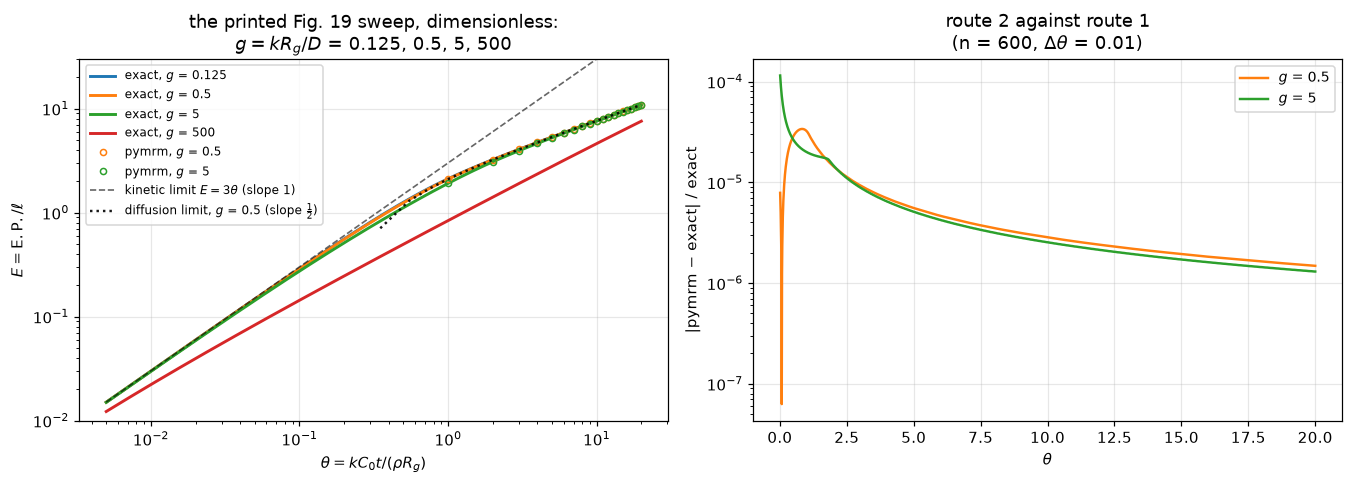

g = 0.5: max rel |E_pymrm - E_exact| over the 1991 steps with 0.1 <= theta <= 20 = 3.39e-05, at theta = 0.83
g = 5: max rel |E_pymrm - E_exact| over the 1991 steps with 0.1 <= theta <= 20 = 6.17e-05, at theta = 0.10


The two routes share no code: one is a finite-volume march through (psi, xi)
with a Newton solve per step, the other a polynomial and one scalar inversion.
They DO share the model statement itself; what that agreement cannot detect
is discussed under Validation.


In [5]:
def ep_error(m, g, lo=0.1):
    """Largest relative |E_pymrm - E_exact| over the steps with theta >= lo."""
    h = m.history()
    sel = h["t"] >= lo - 0.5 * m.dt
    Ee = E_exact(h["t"][sel], g)
    return float(np.max(np.abs(h["EP"][sel] - Ee) / Ee))


def lag_error(m, g, lo=12.0):
    """Mean of theta - E^2/6 over theta >= lo against Delta = 1/4 + g/30, relative."""
    h = m.history()
    sel = h["t"] >= lo - 0.5 * m.dt
    return abs(float(np.mean(h["t"][sel] - h["EP"][sel] ** 2 / 6.0)) - lag(g)) / lag(g)


theta_plot = np.logspace(-2.3, np.log10(20.0), 220)
COL = {0.125: "tab:blue", 0.5: "tab:orange", 5.0: "tab:green", 500.0: "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.5))
for gg in G_SWEEP:
    ax[0].loglog(theta_plot, E_exact(theta_plot, gg), lw=1.9, color=COL[gg], label=f"exact, $g$ = {gg:g}")
for gg, m in runs.items():
    h = m.history()
    ax[0].loglog(h["t"][99::100], h["EP"][99::100], "o", ms=4, mfc="none", color=COL[gg],
                 label=f"pymrm, $g$ = {gg:g}")
ax[0].loglog(theta_plot, 3 * theta_plot, "k--", lw=1.1, alpha=0.6, label=r"kinetic limit $E=3\theta$ (slope 1)")
th_l = np.linspace(0.35, 20, 100)
ax[0].loglog(th_l, np.sqrt(np.maximum(6 * (th_l - lag(0.5)), 0)), "k:", lw=1.6, alpha=0.9,
             label=r"diffusion limit, $g$ = 0.5 (slope $\frac{1}{2}$)")
ax[0].set(xlabel=r"$\theta = kC_0t/(\rho R_g)$", ylabel=r"$E = \mathrm{E.P.}/\ell$", ylim=(1e-2, 30),
          title="the printed Fig. 19 sweep, dimensionless:\n" r"$g = kR_g/D$ = 0.125, 0.5, 5, 500")
ax[0].legend(fontsize=8, loc="upper left")
for gg, m in runs.items():
    h = m.history()
    ax[1].semilogy(h["t"], np.abs(h["EP"] - E_exact(h["t"], gg)) / E_exact(h["t"], gg), lw=1.6, color=COL[gg],
                   label=f"$g$ = {gg:g}")
ax[1].set(xlabel=r"$\theta$", ylabel="|pymrm $-$ exact| / exact",
          title=f"route 2 against route 1\n(n = {N}, $\\Delta\\theta$ = {DT})")
ax[1].legend(fontsize=9)
fig.tight_layout(); plt.show()

HL = {gg: ep_error(m, gg) for gg, m in runs.items()}
claims.value("ep_vs_exact_g05_relmax", HL[0.5])
claims.value("ep_vs_exact_g5_relmax", HL[5.0])
for gg, m in runs.items():
    h = m.history()
    sel = h["t"] >= 0.1 - 0.5 * DT
    rel = np.abs(h["EP"][sel] - E_exact(h["t"][sel], gg)) / E_exact(h["t"][sel], gg)
    print(f"g = {gg:g}: max rel |E_pymrm - E_exact| over the {sel.sum()} steps with 0.1 <= theta <= 20 "
          f"= {HL[gg]:.2e}, at theta = {h['t'][sel][rel.argmax()]:.2f}")
_sh = GrainModel(n=N, L=L_ETA, g=0.5, shield_sink=False, shield_rate=False).march(20.0, DT,
                                                                                   snap_at=(0.25, 1.0, 2.0))
brk("shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)", "ep_vs_exact_g05_relmax",
    ep_error(_sh, 0.5))
_a3 = GrainModel(n=N, L=L_ETA, g=5.0, area_exponent=3).march(20.0, DT)
brk("sink area xi^3 instead of xi^2 (area_exponent=3)", "ep_vs_exact_g5_relmax", ep_error(_a3, 5.0))
print("The two routes share no code: one is a finite-volume march through (psi, xi)")
print("with a Newton solve per step, the other a polynomial and one scalar inversion.")
print("They DO share the model statement itself; what that agreement cannot detect")
print("is discussed under Validation.")

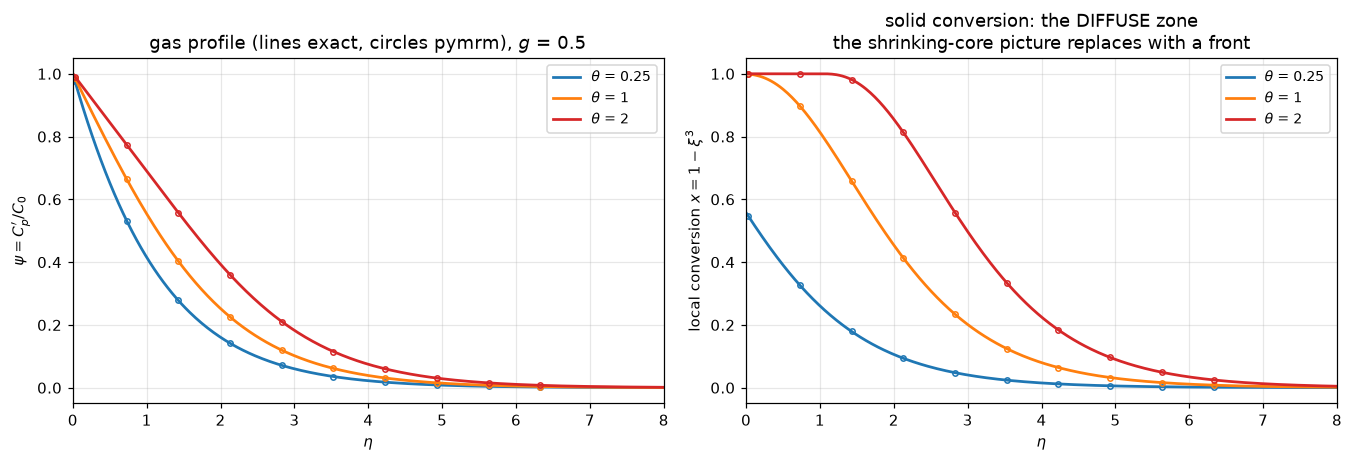

profiles at the cell centres, eta <= 12, theta = 0.25, 1, 2, against the exact solution there:
   n =   300   max |psi - exact| = 1.14e-04   max |xi - exact| = 6.96e-05
   n =   600   max |psi - exact| = 2.92e-05   max |xi - exact| = 1.70e-05
   n =  1200   max |psi - exact| = 7.26e-06   max |xi - exact| = 7.15e-06
   ratios per doubling: psi 3.9, 4.0; xi 4.1, 2.4 (the step is 0.01 throughout)


In [6]:
# ------- profiles: pymrm markers against the exact solution at the cell centres ------
m = runs[0.5]
SNAP = (0.25, 1.0, 2.0)


def profile_dev(mod):
    """Largest |psi - exact| and |xi - exact| at the cell centres with eta <= 12, over SNAP."""
    sel = mod.x_c <= 12.0
    dp = dx = 0.0
    for th in SNAP:
        psi_n, xi_n = mod.snapshots[th]
        pe, xe = profile_exact(mod.x_c[sel], th, 0.5)
        dp, dx = max(dp, np.abs(psi_n[sel] - pe).max()), max(dx, np.abs(xi_n[sel] - xe).max())
    return float(dp), float(dx)


fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.3))
eta_fine = np.linspace(0.0, 8.0, 400)
for th, colr in zip(SNAP, ("tab:blue", "tab:orange", "tab:red")):
    psi_n, xi_n = m.snapshots[th]
    pe, xe = profile_exact(eta_fine, th, 0.5)
    show = m.x_c <= 6.6
    ax[0].plot(eta_fine, pe, lw=1.8, color=colr, label=rf"$\theta$ = {th:g}")
    ax[0].plot(m.x_c[show][::12], psi_n[show][::12], "o", ms=3.5, mfc="none", color=colr)
    ax[1].plot(eta_fine, 1 - xe**3, lw=1.8, color=colr, label=rf"$\theta$ = {th:g}")
    ax[1].plot(m.x_c[show][::12], 1 - np.clip(xi_n[show][::12], 0, 1) ** 3, "o", ms=3.5, mfc="none", color=colr)
ax[0].set(xlabel=r"$\eta$", ylabel=r"$\psi = C_p'/C_0$", xlim=(0, 8),
          title="gas profile (lines exact, circles pymrm), $g$ = 0.5")
ax[1].set(xlabel=r"$\eta$", ylabel=r"local conversion $x = 1-\xi^3$", xlim=(0, 8),
          title="solid conversion: the DIFFUSE zone\nthe shrinking-core picture replaces with a front")
for a in ax:
    a.legend(fontsize=9)
fig.tight_layout(); plt.show()

PD = {N: profile_dev(m)}
for n in (N // 2, 2 * N):
    PD[n] = profile_dev(GrainModel(n=n, L=L_ETA, g=0.5).march(2.0, DT, snap_at=SNAP))
claims.value("profile_psi_dev_n600", PD[N][0])
claims.value("profile_xi_dev_n600", PD[N][1])
_psh = profile_dev(_sh)
brk("shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)", "profile_psi_dev_n600", _psh[0])
brk("shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)", "profile_xi_dev_n600", _psh[1])
print("profiles at the cell centres, eta <= 12, theta = 0.25, 1, 2, against the exact solution there:")
for n in sorted(PD):
    print(f"   n = {n:5d}   max |psi - exact| = {PD[n][0]:.2e}   max |xi - exact| = {PD[n][1]:.2e}")
print("   ratios per doubling: psi " + ", ".join(f"{PD[n][0] / PD[2 * n][0]:.1f}" for n in (N // 2, N))
      + "; xi " + ", ".join(f"{PD[n][1] / PD[2 * n][1]:.1f}" for n in (N // 2, N))
      + f" (the step is {DT} throughout)")

g        theta*      zone width w(g)   [units of ell, x = 1 - xi^3 from 5 % to 95 %]
  0.125      1.021         3.8758
  0.500      1.083         3.9813
  5.000      1.833         5.0611
500.000     84.333        32.8246

For the printed Fig. 7 base case (g = 500): zone width = 32.8 ell = 0.295 cm,
using only printed constants (Dp, Rg, D, k, Sg, FT); no C0 enters, because ell and w
are both C0-free. Szekely & Evans' diffuse-zone claim, made quantitative.


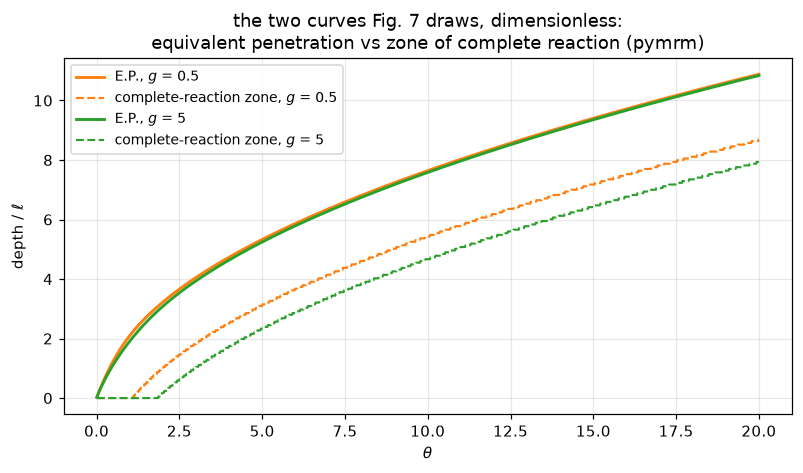

The gap between each pair of curves is the diffuse zone's inventory. Once theta >= theta*,
E^2 = 6 (theta - Delta) exactly, with Delta = 1/4 + g/30 (checked below): a shrinking-core fit
to grain-model data returns a rate constant contaminated by structure, the paper's opening complaint.

Where the grain model departs from each limit (exact route, 5 % bands):
g        kinetic E=3theta good to   sqrt-law within 5 % from   window ratio
  0.125   theta <   0.1449          theta >     0.464                3.2
  0.500   theta <   0.1268          theta >     0.493               3.88
  5.000   theta <   0.0500          theta >     0.835               16.7
500.000   theta <   0.0007          theta >    38.526           5.27e+04



Small $g$: the two classical laws nearly meet, and the grain model is only needed in a window of a factor
3.2 in $\theta$ at $g$ = 0.125 (3.9 at $g$ = 0.5).
Large $g$ (the printed Fig. 7 base case, $g$ = 500): the window spans a factor
5.27e+04 in time, and neither textbook law describes
most of the conversion history.


In [7]:
# ------- the diffuse zone, quantified ---------------------------------------
# The paper's central qualitative claim: reaction occurs in a zone whose
# thickness "may be of the same order as the size of the reacting specimen".
# The exposure profile is a travelling wave, so the width between local
# conversion 5 % and 95 % is one integral over exposure, exactly constant in time.
WG = {gg: zone_width(gg) for gg in G_SWEEP}
print("g        theta*      zone width w(g)   [units of ell, x = 1 - xi^3 from 5 % to 95 %]")
for gg in G_SWEEP:
    print(f"{gg:7.3f}  {1 + gg / 6:9.3f}   {WG[gg]:12.4f}")
W_CM = WG[500.0] * ell
claims.value("zone_width_ell_g500", WG[500.0], rtol=1e-6)
claims.value("zone_width_cm_fig7base", W_CM, rtol=1e-6)
_w1 = zone_width(500.0, xi_exponent=1)
brk("5 % and 95 % levels read on 1 - xi instead of 1 - xi^3 (zone_width(..., xi_exponent=1))",
    "zone_width_ell_g500", _w1)
brk("5 % and 95 % levels read on 1 - xi instead of 1 - xi^3 (zone_width(..., xi_exponent=1))",
    "zone_width_cm_fig7base", _w1 * ell)
print(f"\nFor the printed Fig. 7 base case (g = 500): zone width = {WG[500.0]:.1f} ell = {W_CM:.3f} cm,")
print("using only printed constants (Dp, Rg, D, k, Sg, FT); no C0 enters, because ell and w")
print("are both C0-free. Szekely & Evans' diffuse-zone claim, made quantitative.")

# ------- E.P. and the zone of complete reaction (Fig. 7's two curves) -------
fig, ax = plt.subplots(figsize=(7.4, 4.4))
for gg, mm in runs.items():
    h = mm.history()
    ax.plot(h["t"], h["EP"], lw=1.9, color=COL[gg], label=f"E.P., $g$ = {gg:g}")
    ax.plot(h["t"], h["front"], lw=1.4, ls="--", color=COL[gg], label=f"complete-reaction zone, $g$ = {gg:g}")
ax.set(xlabel=r"$\theta$", ylabel=r"depth / $\ell$",
       title="the two curves Fig. 7 draws, dimensionless:\nequivalent penetration vs zone of complete reaction (pymrm)")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()
print("The gap between each pair of curves is the diffuse zone's inventory. Once theta >= theta*,")
print("E^2 = 6 (theta - Delta) exactly, with Delta = 1/4 + g/30 (checked below): a shrinking-core fit")
print("to grain-model data returns a rate constant contaminated by structure, the paper's opening complaint.")

# ------- where the model departs from each classical limit ------------------
print("\nWhere the grain model departs from each limit (exact route, 5 % bands):")
print("g        kinetic E=3theta good to   sqrt-law within 5 % from   window ratio")
DEP = {gg: departure_thetas(gg) for gg in G_SWEEP}
for gg in G_SWEEP:
    te, tl = DEP[gg]
    print(f"{gg:7.3f}   theta < {te:8.4f}          theta > {tl:9.3f}          {tl / te:9.3g}")
claims.value("theta_early5_g05", DEP[0.5][0], rtol=1e-6)
claims.value("theta_late5_g05", DEP[0.5][1], rtol=1e-6)
for gg, name in ((0.125, "window_ratio_g0125"), (0.5, "window_ratio_g05"), (500.0, "window_ratio_g500")):
    claims.value(name, DEP[gg][1] / DEP[gg][0], rtol=1e-6)
_d90 = {gg: departure_thetas(gg, frac=0.9) for gg in (0.125, 0.5, 500.0)}
_lab = "10 % bands instead of 5 % (departure_thetas(..., frac=0.9))"
brk(_lab, "theta_early5_g05", _d90[0.5][0])
brk(_lab, "theta_late5_g05", _d90[0.5][1])
for gg, name in ((0.125, "window_ratio_g0125"), (0.5, "window_ratio_g05"), (500.0, "window_ratio_g500")):
    brk(_lab, name, _d90[gg][1] / _d90[gg][0])
display(Markdown(rf"""
Small $g$: the two classical laws nearly meet, and the grain model is only needed in a window of a factor
{DEP[0.125][1] / DEP[0.125][0]:.1f} in $\theta$ at $g$ = 0.125 ({DEP[0.5][1] / DEP[0.5][0]:.1f} at $g$ = 0.5).
Large $g$ (the printed Fig. 7 base case, $g$ = 500): the window spans a factor
{DEP[500.0][1] / DEP[500.0][0]:.3g} in time, and neither textbook law describes
most of the conversion history.
"""))

## Validation

Each check names what it can and cannot catch; every registered number has a
row in the break table at the end, which injects one defect per row through an
argument of `model.py` and recomputes the number.

1. **Route 2 against route 1** (above): the finite-volume march against the
   closed form, over the whole conversion history, two values of $g$. What it
   *cannot* catch: a mis-transcription of the model statement itself, which
   both routes inherit; that risk is covered by check 2 and by the
   native-render transcription.
2. **Reduction to the published `B3.1`**: the *simulated* surface-grain
   history $\xi(0,\theta)$ against Yagi & Kunii's Eq. 6 as `B3.1` prints it
   (no film, $\omega = g/6$), a different paper, transcribed independently. The
   algebraic identity between the two printed functions is checked first.
3. **The initial gas profile** against the exact $\sinh$ solution on the
   truncated domain, the grain-model analogue of the paper's printed Eq. 18.
   Blind, by construction, to everything about the march (it is $\theta = 0$)
   and to the area exponent (at $\xi = 1$, $\xi^2 = \xi^3$).
4. **Both axes refined, orders observed**: the grid at a fixed small step
   against the exact solution; the step on a fixed grid from successive
   differences (`pymrm.checks.observed_orders`), which needs no reference.
5. **Mass balance**, in its two parts: the *spatial* identity (boundary influx
   = cell-sink sum at fixed time) telescopes by construction of `construct_div`
   and is labelled structural; the *temporal* closure (time-integrated influx
   vs solid consumed) is a real check of the march and the clamp, and the one
   that catches Eqs. 21 and 27 printed with inconsistent resistances.
6. **Dimensional closure**: the same class run in cgs units on the printed
   Fig. 7 base case, against $\ell\,E_\mathrm{exact}(t/\tau)$, testing the
   $\ell,\tau,g$ reduction algebra end to end. $C_0$ is not printed in the
   paper, so a **chosen** illustrative $C_0$ (ideal gas at roughly ambient
   pressure and furnace temperature) is used and labelled; the check's verdict
   is independent of that choice, because both routes receive it.

In [8]:
print("1. G(xi)/theta* against B3.1's eq. 6, no film (gamma = 1e12), omega = g/6")
XI_T = np.linspace(0.0, 1.0, 1001)


def eq6_identity_gap(cubic="printed"):
    """Largest |G(xi)/theta* - eq. 6| over xi in [0, 1] and the four printed g."""
    return max(float(np.abs(G_of_xi(XI_T, gg) / (1 + gg / 6) - yagi_kunii_eq6(XI_T, gg / 6, 1e12, cubic=cubic)).max())
               for gg in G_SWEEP)


ID_GAP = eq6_identity_gap()
claims.bound("b31_identity_structural", ID_GAP, max=1e-11, basis="theory",
             note="eq. 6 at gamma = 1e12 differs from its no-film limit in proportion to 1/gamma")
brk("eq. 6 cubic coefficient read as omega (1 - gamma) (yagi_kunii_eq6(..., cubic='misread'))",
    "b31_identity_structural", eq6_identity_gap(cubic="misread"))
print(f"   max |diff| below 1e-11 (here {ID_GAP:.1e}): the film term at gamma = 1e12, not round-off.")
print(f"   B3.1 checks its eq. 6 against an integration of the three resistances (its committed")
print(f"   gap: {B31['eq6_vs_integrated_worst']:.1e}).\n")

print("2. surface-grain history vs B3.1 eq. 6 (no film, omega = g/6)")
OM05 = 0.5 / 6


def surface_error(mod, read="xi_s"):
    """Largest |theta(eq. 6 at the surface xi) - theta| / theta* over the steps with xi > 1e-3."""
    h = mod.history()
    k = h[read] > 1e-3
    th6 = yagi_kunii_eq6(np.clip(h[read][k], 0, 1), OM05, 1e12) * (1 + OM05)
    return float(np.max(np.abs(th6 - h["t"][k])) / (1 + OM05))


EPS = np.finfo(float).eps
NS_SURF = (150, 300, 600)
SURF = {n: GrainModel(n=n, L=30.0, g=0.5).march(1.0, 0.0025) for n in NS_SURF}
SE = {n: surface_error(SURF[n]) for n in NS_SURF}
SE0 = {n: surface_error(SURF[n], read="xi_0") for n in NS_SURF}
for i, n in enumerate(NS_SURF):
    o = f"   order = {np.log2(SE[NS_SURF[i - 1]] / SE[n]):.2f}" if i else ""
    print(f"   n = {n:4d}   max |theta(eq.6) - theta| / theta* = {SE[n]:.3e}{o}")
SURF_ORDER = float(np.log2(SE[300] / SE[600]))
claims.value("surface_b31_relmax_n600", SE[600])
claims.bound("surface_b31_finest_over_roundoff", SE[600] / (600**2 * EPS), min=1e3, basis="theory",
             note="finest error of the surface ladder over n^2 eps at 600 cells")
claims.bound("surface_b31_order_n600", SURF_ORDER, min=1.85, max=2.05, basis="theory",
             note="second-order scheme and extrapolation, approached from below; 300 and 600 cells")
brk("surface xi read as the first cell's value (xi_surface(read='cell'))", "surface_b31_relmax_n600", SE0[600])
brk("surface xi read as the first cell's value (xi_surface(read='cell'))", "surface_b31_order_n600",
    np.log2(SE0[300] / SE0[600]))
brk("surface history compared with itself instead of eq. 6 (zero error)", "surface_b31_finest_over_roundoff",
    0.0)
brk("surface concentration 10 % low (GrainModel(..., c_surf=0.9))", "surface_b31_relmax_n600",
    surface_error(GrainModel(n=600, L=30.0, g=0.5, c_surf=0.9).march(1.0, 0.0025)))
_SE_dt = surface_error(GrainModel(n=600, L=30.0, g=0.5).march(1.0, 0.00125))
print(f"   with half the step on 600 cells: {_SE_dt:.3e}, so the time step contributes "
      f"{abs(_SE_dt - SE[600]) / SE[600]:.1%} of it.")
print("   The grain model reduces to the published shrinking core at the exposed face;")
print("   xi is extrapolated to eta = 0 from the first two cells, and that read-off and the")
print("   grid refine away together. The first cell's value alone converges at first order")
print(f"   (orders {np.log2(SE0[150] / SE0[300]):.2f}, {np.log2(SE0[300] / SE0[600]):.2f}).\n")

print("3. theta = 0 gas profile vs exact sinh(L - eta)/sinh(L)")


def init_error(n, L=L_ETA, **kw):
    mm = GrainModel(n=n, L=L, g=0.5, **kw)
    return float(np.abs(mm.psi - np.sinh(L - mm.x_c) / np.sinh(L)).max())


INIT = {n: init_error(n) for n in (150, 300, 600)}
for n in INIT:
    o = f"   order = {np.log2(INIT[n // 2] / INIT[n]):.2f}" if n > 150 else ""
    print(f"   n = {n:4d}   max |psi - exact| = {INIT[n]:.3e}{o}")
claims.value("init_profile_relmax_n600", INIT[600])
brk("spherical divergence for the slab (GrainModel(..., nu=2))", "init_profile_relmax_n600", init_error(600, nu=2))
brk("surface concentration 10 % low (GrainModel(..., c_surf=0.9))", "init_profile_relmax_n600",
    init_error(600, c_surf=0.9))
brk("far boundary zero flux instead of psi = 0 (GrainModel(..., far_bc='neumann'))", "init_profile_relmax_n600",
    init_error(600, far_bc="neumann"))
print("   (the paper prints the pore-model twin of this profile as its Eq. 18; the orders")
print("   rise towards 2, the error peaking near eta = 1)")

1. G(xi)/theta* against B3.1's eq. 6, no film (gamma = 1e12), omega = g/6
   max |diff| below 1e-11 (here 4.4e-13): the film term at gamma = 1e12, not round-off.
   B3.1 checks its eq. 6 against an integration of the three resistances (its committed
   gap: 6.9e-16).

2. surface-grain history vs B3.1 eq. 6 (no film, omega = g/6)


   n =  150   max |theta(eq.6) - theta| / theta* = 6.185e-03
   n =  300   max |theta(eq.6) - theta| / theta* = 1.662e-03   order = 1.90
   n =  600   max |theta(eq.6) - theta| / theta* = 4.324e-04   order = 1.94


   with half the step on 600 cells: 4.327e-04, so the time step contributes 0.1% of it.
   The grain model reduces to the published shrinking core at the exposed face;
   xi is extrapolated to eta = 0 from the first two cells, and that read-off and the
   grid refine away together. The first cell's value alone converges at first order
   (orders 0.98, 0.99).

3. theta = 0 gas profile vs exact sinh(L - eta)/sinh(L)
   n =  150   max |psi - exact| = 6.017e-04
   n =  300   max |psi - exact| = 1.759e-04   order = 1.77
   n =  600   max |psi - exact| = 4.786e-05   order = 1.88
   (the paper prints the pore-model twin of this profile as its Eq. 18; the orders
   rise towards 2, the error peaking near eta = 1)


In [9]:
print("4a. grid refinement, Delta_theta = 2e-3 fixed, theta_end = 2, vs exact")
NS_G = (75, 150, 300, 600)
EG = {n: GrainModel(n=n, L=30.0, g=0.5).march(2.0, 2e-3).EP() for n in (*NS_G, 601)}
Eex2 = float(E_exact(2.0, 0.5))
for i, n in enumerate(NS_G):
    e = abs(EG[n] - Eex2) / Eex2
    o = f"   order = {np.log2(abs(EG[NS_G[i - 1]] - Eex2) / abs(EG[n] - Eex2)):.3f}" if i else ""
    print(f"   n = {n:4d}   rel err = {e:.3e}{o}")


def grid_order(E_ref):
    return float(np.log2(abs(EG[300] - E_ref) / abs(EG[600] - E_ref)))


claims.bound("grid_order_observed", grid_order(Eex2), min=1.9, max=2.1, basis="theory",
             note="error against the exact E at theta = 2, 300 and 600 cells")
claims.bound("grid_finest_over_roundoff", abs(EG[300] - EG[600]) / EG[600] / (600**2 * EPS), min=1e3,
             basis="theory", note="finest relative difference of the ladder over n^2 eps at 600 cells")
brk("exact E taken one step late (E_exact(2 + 2e-3))", "grid_order_observed", grid_order(float(E_exact(2.002, 0.5))))
brk("grid ladder whose last rung is 601 cells after 600", "grid_finest_over_roundoff",
    abs(EG[600] - EG[601]) / EG[601] / (601**2 * EPS))

print("\n4b. time-step refinement, n = 300 fixed, orders from successive differences")
KS = (25, 50, 100, 200, 400)
TL = {k: GrainModel(n=300, L=30.0, g=0.5).march(2.0, 2.0 / k) for k in (*KS, 401)}
OD = observed_orders(lambda k: TL[k].EP(), KS)
for k, v in zip(KS, OD["values"]):
    print(f"   dt = {2.0 / k:.4f}   E = {v:.10f}")
print("   observed orders " + ", ".join(f"{o:.3f}" for o in OD["orders"]))
claims.bound("dt_order_observed", OD["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="trapezoidal rule, successive differences of E(theta = 2) at 100, 200, 400 steps")
claims.bound("dt_finest_over_roundoff", abs(TL[200].EP() - TL[400].EP()) / TL[400].EP() / (300**2 * EPS),
             min=1e3, basis="theory", note="finest relative difference of the ladder over n^2 eps at 300 cells")
_be = observed_orders(lambda k: GrainModel(n=300, L=30.0, g=0.5, theta_scheme=1.0).march(2.0, 2.0 / k).EP(),
                      (100, 200, 400))
brk("backward Euler for the grain equation (theta_scheme=1)", "dt_order_observed", _be["orders"][-1])
brk("step ladder whose last rung is 401 steps after 400", "dt_finest_over_roundoff",
    abs(TL[400].EP() - TL[401].EP()) / TL[401].EP() / (300**2 * EPS))
print(f"   theta_end = 2 crosses the surface burnout theta* = {1 + 0.5 / 6:.3f}, so these orders include")
print(f"   the complementarity clamp firing. Backward Euler gives {_be['orders'][-1]:.2f}.")
print(f"   At the grid study's step (2e-3) the time error is about "
      f"{abs(OD['extrapolated'] - TL[400].EP()) / Eex2 * (2e-3 / 5e-3) ** 2:.0e} of E,")
print(f"   against a grid error of {abs(EG[600] - Eex2) / Eex2:.1e} on 600 cells.")

4a. grid refinement, Delta_theta = 2e-3 fixed, theta_end = 2, vs exact


   n =   75   rel err = 6.238e-04
   n =  150   rel err = 1.613e-04   order = 1.952
   n =  300   rel err = 4.015e-05   order = 2.006
   n =  600   rel err = 1.005e-05   order = 1.998

4b. time-step refinement, n = 300 fixed, orders from successive differences


   dt = 0.0800   E = 3.2251946603
   dt = 0.0400   E = 3.2250729336
   dt = 0.0200   E = 3.2250425740
   dt = 0.0100   E = 3.2250349991
   dt = 0.0050   E = 3.2250331027
   observed orders 2.003, 2.003, 1.998


   theta_end = 2 crosses the surface burnout theta* = 1.083, so these orders include
   the complementarity clamp firing. Backward Euler gives 1.00.
   At the grid study's step (2e-3) the time error is about 3e-08 of E,
   against a grid error of 1.0e-05 on 600 cells.


In [10]:
print("5a. spatial identity at fixed time (STRUCTURAL: the divergence telescopes):")
BAL = GrainModel(n=300, L=30.0, g=0.5).balance_gap()
claims.bound("spatial_balance_gap", BAL, max=1e-12, basis="identity", structural=True,
             note="(influx - outflux) - sum(sink dx) at theta = 0; round-off only")
print(f"   (influx - outflux) - sum(sink * dx) below 1e-12 (here {BAL:.1e}).")
print("   This cannot fail while the operators come from construct_grad / construct_div;")
print("   it shows the flux post-processing reads the operator the solve uses.\n")

print("5b. temporal closure: integral of boundary influx vs solid consumed")
MB = {}
for k in (50, 100, 200, 400):
    mm = TL[k]
    MB[k] = abs(mm.I_gas - mm.solid_consumed()) / mm.solid_consumed()
    o = f"   order = {np.log2(MB[k // 2] / MB[k]):.2f}" if k > 50 else ""
    print(f"   dt = {2.0 / k:.3f}   rel gap = {MB[k]:.3e}{o}")
claims.value("mass_balance_rel_dt5e3", MB[400])
_mm = GrainModel(n=300, L=30.0, g=0.5, shield_rate=False).march(2.0, 0.005)
_mb_bad = abs(_mm.I_gas - _mm.solid_consumed()) / _mm.solid_consumed()
brk("Eq. 21 without the (1 - xi) that Eq. 27 keeps (shield_rate=False)", "mass_balance_rel_dt5e3", _mb_bad)
print("   Converges at the scheme's order: the march consumes gas and solid consistently,")
print("   including through grain-exhaustion events. With Eq. 21's resistance written")
print(f"   without the (1 - xi) that Eq. 27 keeps, the gap is {_mb_bad:.1e}.\n")

5a. spatial identity at fixed time (STRUCTURAL: the divergence telescopes):
   (influx - outflux) - sum(sink * dx) below 1e-12 (here 4.6e-15).
   This cannot fail while the operators come from construct_grad / construct_div;
   it shows the flux post-processing reads the operator the solve uses.

5b. temporal closure: integral of boundary influx vs solid consumed
   dt = 0.040   rel gap = 6.561e-05
   dt = 0.020   rel gap = 1.642e-05   order = 2.00
   dt = 0.010   rel gap = 4.102e-06   order = 2.00
   dt = 0.005   rel gap = 1.026e-06   order = 2.00


   Converges at the scheme's order: the march consumes gas and solid consistently,
   including through grain-exhaustion events. With Eq. 21's resistance written
   without the (1 - xi) that Eq. 27 keeps, the gap is 3.4e-01.



In [11]:
print("6. dimensional run, printed Fig. 7 constants, CHOSEN C0 = %.1e mol/cm3" % C0)


def dimensional_error(dtf, L_ell=30.0):
    """Window maximum and the state at the common time t = 0.2 tau (relative |E.P. - ell E_exact(t/tau)|).

    Returns the largest error over the recorded times in [0.1, 5] tau, the time of that
    maximum, the error at 5 tau, the error at t = 0.2 tau (a step time of every rung)
    and E.P. itself at t = 0.2 tau.
    """
    sc = scales(**FIG7, rho=RHO, C0=C0)
    md = GrainModel(n=600, L=L_ell * sc["ell"], g=sc["g"], diff=sc["Deff"],
                    sink_pref=3 * (1 - FIG7["Sg"]) * FIG7["k"] / FIG7["Rg"],
                    rate_pref=FIG7["k"] / (RHO * FIG7["Rg"]), c_surf=C0)
    md.march(5.0 * sc["tau"], dtf * sc["tau"])
    h = md.history()
    sel = h["t"] >= 0.1 * sc["tau"] * (1.0 - 1e-9)
    pred = sc["ell"] * E_exact(h["t"][sel] / sc["tau"], sc["g"])
    rel = np.abs(h["EP"][sel] - pred) / pred
    i2 = int(round(0.2 / dtf)) - 1                                   # step k lands on t = (k + 1) dt
    assert abs(h["t"][i2] / sc["tau"] - 0.2) < 1e-9
    e2 = abs(h["EP"][i2] - sc["ell"] * E_exact(h["t"][i2] / sc["tau"], sc["g"])) / (
        sc["ell"] * E_exact(h["t"][i2] / sc["tau"], sc["g"]))
    return (float(rel.max()), float(h["t"][sel][rel.argmax()] / sc["tau"]), float(rel[-1]), float(e2),
            float(h["EP"][i2]))


print(f"   ell = {ell:.4e} cm, tau = {SC['tau']:.3f} s, g = {SC['g']:g}")
DIM = {dtf: dimensional_error(dtf) for dtf in (0.008, 0.004, 0.002, 0.001)}
for dtf, (e, at, end, e2, _) in DIM.items():
    print(f"   dt = {dtf:.3f} tau   max rel |E.P. - ell*E_exact(t/tau)| over t >= 0.1 tau = {e:.2e} at "
          f"t/tau = {at:.2f}, {end:.1e} at t = 5 tau; at t = 0.2 tau {e2:.2e}")
_dk = sorted(DIM, reverse=True)
DIM_ERR_ORDERS = [float(np.log2(DIM[a][3] / DIM[b][3])) for a, b in zip(_dk, _dk[1:])]
_dd = [abs(DIM[a][4] - DIM[b][4]) for a, b in zip(_dk, _dk[1:])]          # successive differences of E.P.
DIM_ORDERS = [float(np.log2(a / b)) for a, b in zip(_dd, _dd[1:])]
print("   orders from the errors at t = 0.2 tau: " + ", ".join(f"{o:.2f}" for o in DIM_ERR_ORDERS)
      + " (the last pair feels the 600-cell spatial error)")
print("   orders from successive differences at t = 0.2 tau (spatial error cancels): "
      + ", ".join(f"{o:.3f}" for o in DIM_ORDERS))
claims.value("dimensional_closure_relmax", DIM[0.002][0])
claims.bound("dimensional_order_observed", DIM_ORDERS[-1], min=1.9, max=2.1, basis="theory",
             note="successive differences of E.P. at the common step time t = 0.2 tau, dt = 0.004, 0.002, 0.001 tau")
claims.bound("dimensional_finest_over_roundoff", _dd[-1] / (DIM[0.001][4] * 600**2 * EPS), min=1e3, basis="theory",
             note="finest relative difference of the ladder at t = 0.2 tau over n^2 eps at 600 cells")
_dt6 = {dtf: dimensional_error(dtf, L_ell=6.0) for dtf in (0.004, 0.002)}
brk("domain truncated at 6 ell instead of 30 ell (L = 6 ell)", "dimensional_closure_relmax", _dt6[0.002][0])


def _ep_at_02(dtf, theta_scheme):
    """E.P. at t = 0.2 tau of the dimensional run (for the backward-Euler break row)."""
    md = GrainModel(n=600, L=30.0 * SC["ell"], g=SC["g"], diff=SC["Deff"],
                    sink_pref=3 * (1 - FIG7["Sg"]) * FIG7["k"] / FIG7["Rg"],
                    rate_pref=FIG7["k"] / (RHO * FIG7["Rg"]), c_surf=C0, theta_scheme=theta_scheme)
    md.march(0.2 * SC["tau"], dtf * SC["tau"])
    return float(md.history()["EP"][-1])


_be_ep = [_ep_at_02(d, 1.0) for d in (0.004, 0.002, 0.001)]
brk("backward Euler for the grain equation in the dimensional run (theta_scheme=1)", "dimensional_order_observed",
    np.log2(abs(_be_ep[0] - _be_ep[1]) / abs(_be_ep[1] - _be_ep[2])))
brk("finest rung differenced with itself (zero difference)", "dimensional_finest_over_roundoff", 0.0)
print("   The window maximum sits at its start and refines away; the orders are taken at one time")
print("   that every rung lands on, from successive differences so the fixed grid's error cancels. The march never")
print("   sees ell, tau or theta (it runs in cm and seconds), so this closes the reduction")
print("   algebra end to end. The domain is 30 ell; on 6 ell the check fails")
print("   (break table): the truncation hazard no interior residual sees.\n")

print("late-time asymptote: mean of (theta - E^2/6) on 12 <= theta <= 20 against Delta = 1/4 + g/30")
LAG = {gg: lag_error(m, gg) for gg, m in runs.items()}
for gg in runs:
    print(f"   g = {gg:g}: exact Delta = {lag(gg):.4f}, pymrm relative deviation {LAG[gg]:.1e}")
claims.value("lag_fit_rel_g05", LAG[0.5])
claims.value("lag_fit_rel_g5", LAG[5.0])
brk("shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)", "lag_fit_rel_g05",
    lag_error(_sh, 0.5))
brk("sink area xi^3 instead of xi^2 (area_exponent=3)", "lag_fit_rel_g5", lag_error(_a3, 5.0))
print("   On the exact route E^2/6 = theta - Delta holds exactly beyond theta*, so the deviation")
print("   is the march's discretisation error (a diagnostic on this page's own curve).")

6. dimensional run, printed Fig. 7 constants, CHOSEN C0 = 1.0e-05 mol/cm3
   ell = 8.9893e-03 cm, tau = 1.750 s, g = 500


   dt = 0.008 tau   max rel |E.P. - ell*E_exact(t/tau)| over t >= 0.1 tau = 3.43e-03 at t/tau = 0.10, 2.4e-05 at t = 5 tau; at t = 0.2 tau 1.52e-03
   dt = 0.004 tau   max rel |E.P. - ell*E_exact(t/tau)| over t >= 0.1 tau = 9.07e-04 at t/tau = 0.10, 6.6e-06 at t = 5 tau; at t = 0.2 tau 3.83e-04
   dt = 0.002 tau   max rel |E.P. - ell*E_exact(t/tau)| over t >= 0.1 tau = 2.30e-04 at t/tau = 0.10, 2.1e-06 at t = 5 tau; at t = 0.2 tau 9.82e-05
   dt = 0.001 tau   max rel |E.P. - ell*E_exact(t/tau)| over t >= 0.1 tau = 6.07e-05 at t/tau = 0.10, 9.9e-07 at t = 5 tau; at t = 0.2 tau 2.69e-05
   orders from the errors at t = 0.2 tau: 1.99, 1.96, 1.87 (the last pair feels the 600-cell spatial error)
   orders from successive differences at t = 0.2 tau (spatial error cancels): 1.995, 1.999


   The window maximum sits at its start and refines away; the orders are taken at one time
   that every rung lands on, from successive differences so the fixed grid's error cancels. The march never
   sees ell, tau or theta (it runs in cm and seconds), so this closes the reduction
   algebra end to end. The domain is 30 ell; on 6 ell the check fails
   (break table): the truncation hazard no interior residual sees.

late-time asymptote: mean of (theta - E^2/6) on 12 <= theta <= 20 against Delta = 1/4 + g/30
   g = 0.5: exact Delta = 0.2667, pymrm relative deviation 2.2e-04
   g = 5: exact Delta = 0.4167, pymrm relative deviation 1.2e-04
   On the exact route E^2/6 = theta - Delta holds exactly beyond theta*, so the deviation
   is the march's discretisation error (a diagnostic on this page's own curve).


### The break table

Every number above is registered as a claim; each row injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it.

In [12]:
print(f"{'injected defect':<96} {'claim':<28} {'clean':>11} {'broken':>11}  caught")
for row, metric, clean, broken, caught in BREAK:
    if claims.metrics[metric]["kind"] == "bound":
        shown, br = f"(here {clean:.3g})", f"{float(broken):.3g}"
    else:
        shown, br = f"{float(clean):11.5g}", f"{float(broken):11.5g}"
    print(f"{row[:96]:<96} {metric[:28]:<28} {shown:>11} {br:>11}  {'yes' if caught else 'NO'}")
_caught = {mt for _, mt, _, _, c in BREAK if c}
_open = sorted(k for k in claims.metrics if k not in _caught and not claims.metrics[k].get("structural"))
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"open: {', '.join(_open) or 'none'}")
print("rows that do not fail their claim: "
      + ("; ".join(f"{r} -> {mt}" for r, mt, _, _, c in BREAK if not c) or "none"))

injected defect                                                                                  claim                              clean      broken  caught
NumJac route with the sink area xi^3 (GrainModel(..., area_exponent=3))                          numjac_route_gap             (here 5.72e-15)      0.0922  yes
d(sink)/d(xi) dropped from the analytic Jacobian (GrainModel(..., jac_defect='drop_dsink_dxi'))  jacobian_gap_vs_numjac       (here 8.96e-07)       0.554  yes
shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)                   ep_vs_exact_g05_relmax        3.3897e-05     0.16544  yes
sink area xi^3 instead of xi^2 (area_exponent=3)                                                 ep_vs_exact_g5_relmax         6.1729e-05     0.12261  yes
shell resistance g xi for g xi (1 - xi) (shield_sink=False, shield_rate=False)                   profile_psi_dev_n600          2.9228e-05    0.054493  yes
shell resistance g xi for g xi (1 - xi) (shield_sink=False,

**What the rows that do not fail establish.** The far-boundary row: at
$L = 35$ the profile has decayed to about $e^{-35}$, so the truncated Dirichlet
and Neumann conditions are equivalent. That is the domain-truncation statement,
demonstrated rather than asserted, and a warning that no check on this page could
catch a wrong far-field condition on an adequately long domain; the domain
length itself is tested by the dimensional row, where a short domain fails.

**What no check on this page can catch**: a mis-statement of the model shared by
both routes AND by `B3.1`'s closed form, i.e. an error in the common
shrinking-core closure itself. That is bounded by `B3.1`'s own independent
validation and by the native-render transcription shown in "The published
model".

## What pymrm adds

**To the semi-infinite grain model's penetration curve: nothing, and the page
shows it.** The exact law $E = \sqrt{6X(\theta)}$, derived here from the
paper's own Eqs. 21 and 27 via the exposure transformation, replaces the
numerical integration Szekely and Evans ran, for their exact formulation
(quasi-steady gas, first-order kinetics). The closed form is this page's
contribution; it is a near relative of results in the later Sohn-Szekely
lineage (the additive-reaction-time law, planned `B3.4`), and no novelty is
claimed for it.

**What the pymrm march adds is everything the transformation cannot survive.**
The exposure trick fails the moment the gas equation gains a holdup term, the
kinetics stop being first order, the structure evolves (the authors' own
assumption 5), or the geometry becomes a finite pellet (Part II), while the
finite-volume march above extends to each of those by changing a coefficient
or `nu`. The page's value is having the two side by side: an exact law to
stand on, and the general machine validated against it at second order in both
axes before any generalisation is attempted.

**What the analysis adds beyond the paper**: the diffuse zone the paper could
only plot is quantified, a travelling reaction zone of exactly constant width
$w(g)\,\ell$ (for the printed base case, from printed constants alone, no $C_0$
required: the value is printed in Results), the lag $\Delta = 1/4 + g/30$
separating the grain model from the specimen-scale shrinking core exactly once
the surface grains are consumed, and the 5 % departure map showing the window
where neither textbook limit works growing with $g$ over many orders of
magnitude in time, up to the paper's own base case $g = 500$ (values in Results).

**Honesty**: nothing here is validated against measurement; the source
contains none. The paper's own claim for the model is reproducing "general
trends" with "reasonable values", and this page inherits exactly that
epistemic status, plus internal mathematical consistency.

## Reuse

**`E_exact(theta, g)` is the whole semi-infinite grain model**: one parameter
in, penetration history out, with `G_of_xi`, `X_of_theta`, `xi_of_zeta`,
`profile_exact` and `zone_width` as by-products. `B3.4` (Sohn's law of
additive reaction times, whose paper cites this one) should import these as
its exact reference. Anyone fitting shrinking-core rate constants to
porous-solid data can use $\Delta = 1/4 + g/30$ to see how much structure their
"rate constant" has absorbed.

**`GrainModel` is the reusable pymrm piece**: a 1-D quasi-steady field coupled
to a pointwise internal-state ODE with a complementarity constraint, the
shape of every deactivation, sorption-front and product-layer problem in
section B. Its two fields share one grid through `BlockLayout.from_fields`,
and the pointwise $2\times2$ Jacobian blocks go in with
`construct_coefficient_matrix`; the complementarity row switches between the
grain equation's derivatives and those of $\xi$ itself. To make it a finite
spherical pellet (Part II, `B3.4`'s geometry): `nu=2`, a symmetry condition
`{"a": 1, "b": 0, "d": 0}` at the centre, and the film condition of `B3.1` at
the surface.

**Three traps; (i) and (iii) have a row in the break table.** (i) `nu` is the *sample*
geometry, not the grain geometry: the grains' sphericity is in the closure, and
`nu=2` here wrecks even the initial profile. (ii) Two fields on one grid
interleave as `(n, 2)`; a bare 1-D shape `(2n,)` for `NumJac` would couple the
spatial axis in full and build a dense Jacobian. (iii) The far boundary of a
truncated semi-infinite domain is *undetectable* by any interior check once $L$
is adequate: choose $L$ from the physics ($E(\theta_\mathrm{end})$ plus a tail
allowance), because no residual will warn you.

**Reading this paper.** Native resolution is 300 ppi CCITT-G4; render at 300
and **crop before reading numerics**: the mid-dot decimals ($2\!\cdot\!0
\times 10^{-4}$) vanish at page scale and the text layer is unusable for
mathematics. Part II (*CES* **26** (1971) 1901) has no readable scan in this
collection; its Elsevier api-text drops decimal points and must not be used
for constants.

**Related pages.** [`B3.1`](../B3.1-shrinking-core/) (the closure, and the
model this one reduces to at the exposed face), `B3.4` (planned: the
closed-form bridge between the two pictures), `B1.1` (the porous-catalyst
counterpart where the solid is not consumed), `B2.2` (deactivation fronts,
same mathematical shape).

**Cite the source, not this page:** Szekely, J. and Evans, J. W., *A
structural model for gas-solid reactions with a moving boundary*, Chemical
Engineering Science **25**(6), 1091-1107 (1970),
doi:10.1016/0009-2509(70)85053-9.

In [13]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B3.2:
  numjac_route_gap                 = (here 5.7e-15)   bound  bound <= 1e-10 [tolerance]
  jacobian_gap_vs_numjac           = (here 9.0e-07)   bound  bound <= 1e-05 [tolerance]
  ep_vs_exact_g05_relmax           = 3.3897e-05       value  rtol 0.05
  ep_vs_exact_g5_relmax            = 6.1729e-05       value  rtol 0.05
  profile_psi_dev_n600             = 2.9228e-05       value  rtol 0.05
  profile_xi_dev_n600              = 1.7005e-05       value  rtol 0.05
  zone_width_ell_g500              = 32.825           value  rtol 1e-06
  zone_width_cm_fig7base           = 0.29507          value  rtol 1e-06
  theta_early5_g05                 = 0.12683          value  rtol 1e-06
  theta_late5_g05                  = 0.49269          value  rtol 1e-06
  window_ratio_g0125               = 3.2038           value  rtol 1e-06
  window_ratio_g05                 = 3.8846           value  rtol 1e-06
  window_ratio_g500                = 52663            value  rtol 1e-06
  b31_identity_stru